In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [31]:
df = pd.read_csv(Path('/Users/anshjj/Downloads/Campusx_Project/data/Cleaned/property_v2.csv'))

In [32]:
df.head()

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,...,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area
0,flat,indiabulls centrum park,2.45,NaN,sector 103,2875.25,Super Built up area 2875(267.1 sq.m.),4,4,3.0,...,1,1,1,1,0,0,38,2875.0,NaN,NaN
1,house,project mianwali colony,2.00,14815.0,mianwali colony,1350.00,Built Up area: 1350 (125.42 sq.m.),5,5,2.0,...,0,0,0,0,0,0,0,NaN,1350.0,NaN
2,flat,paras dews,1.50,NaN,sector 106,2355.16,Super Built up area 2355(218.79 sq.m.)Built Up...,4,6,3.0,...,0,0,0,1,0,0,174,2355.0,1535.0,1403.000000
3,flat,rof ananda,0.38,NaN,sector 95,549.21,Carpet area: 549.17 (51.02 sq.m.),2,2,1.0,...,0,0,0,0,0,1,0,NaN,NaN,549.174178
4,flat,sare homes,0.68,NaN,sector 92,1298.21,Carpet area: 1298 (120.59 sq.m.),3,3,2.0,...,1,0,0,0,0,1,100,NaN,NaN,1298.000000


In [33]:
df.shape

(3903, 23)

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3903 entries, 0 to 3902
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   property_type        3903 non-null   object 
 1   society              3900 non-null   object 
 2   price                3874 non-null   float64
 3   price_per_sqft       945 non-null    float64
 4   sector               3903 non-null   object 
 5   area                 3874 non-null   float64
 6   areaWithType         3903 non-null   object 
 7   bedRoom              3903 non-null   int64  
 8   bathroom             3903 non-null   int64  
 9   balcony              3810 non-null   float64
 10  floorNum             3883 non-null   float64
 11  facing               2751 non-null   object 
 12  agePossession        3903 non-null   object 
 13  Pooja Room           3903 non-null   int64  
 14  Study Room           3903 non-null   int64  
 15  Store Room           3903 non-null   i

In [35]:
df.duplicated().sum()

np.int64(126)

In [36]:
df.drop_duplicates(inplace=True)

In [37]:
df.head()

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,...,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area
0,flat,indiabulls centrum park,2.45,NaN,sector 103,2875.25,Super Built up area 2875(267.1 sq.m.),4,4,3.0,...,1,1,1,1,0,0,38,2875.0,NaN,NaN
1,house,project mianwali colony,2.00,14815.0,mianwali colony,1350.00,Built Up area: 1350 (125.42 sq.m.),5,5,2.0,...,0,0,0,0,0,0,0,NaN,1350.0,NaN
2,flat,paras dews,1.50,NaN,sector 106,2355.16,Super Built up area 2355(218.79 sq.m.)Built Up...,4,6,3.0,...,0,0,0,1,0,0,174,2355.0,1535.0,1403.000000
3,flat,rof ananda,0.38,NaN,sector 95,549.21,Carpet area: 549.17 (51.02 sq.m.),2,2,1.0,...,0,0,0,0,0,1,0,NaN,NaN,549.174178
4,flat,sare homes,0.68,NaN,sector 92,1298.21,Carpet area: 1298 (120.59 sq.m.),3,3,2.0,...,1,0,0,0,0,1,100,NaN,NaN,1298.000000


### property_type

<Axes: xlabel='property_type'>

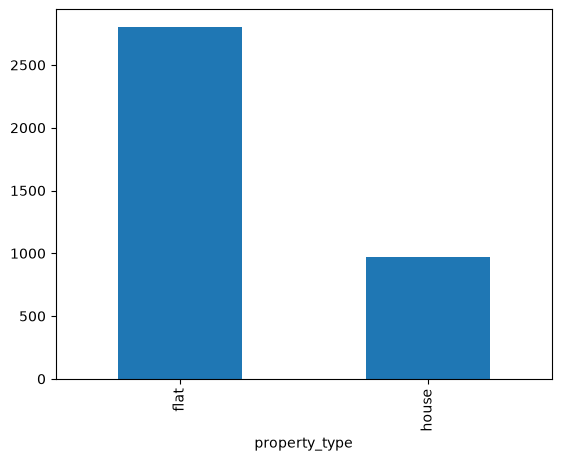

In [38]:
df['property_type'].value_counts().plot(kind='bar',)

#### Observations

- Flats are in majority(75 percent) and there are less number of houses(~25 percent)
- No missing values

### society

In [39]:
df['society'].value_counts().shape

(654,)

In [40]:
df['society'].value_counts()

society
independent             579
m                       152
tulip violet             75
ss the leaf              73
dlf new town heights     42
                       ... 
vipul world floors        1
rail vihar cghs           1
aipl joy square           1
bhim nagar society        1
aditya apartment          1
Name: count, Length: 654, dtype: int64

In [41]:
df[df['society'] != 'independent']['society'].value_counts(normalize=True).cumsum().head(75)

society
m                                       0.047574
tulip violet                            0.071049
ss the leaf                             0.093897
shapoorji pallonji joyville gurugram    0.107042
dlf new town heights                    0.120188
                                          ...   
unitech uniworld resorts                0.529264
mvn athens                              0.533020
breez global heights                    0.536776
ireo the corridors                      0.540532
central park flower valley              0.544288
Name: proportion, Length: 75, dtype: float64

In [42]:
society_counts = df['society'].value_counts()

# Frequency distribution for societies
frequency_bins = {
    "Very High (>100)": (society_counts > 100).sum(),
    "High (50-100)": ((society_counts >= 50) & (society_counts <= 100)).sum(),
    "Average (10-49)": ((society_counts >= 10) & (society_counts < 50)).sum(),
    "Low (2-9)": ((society_counts > 1) & (society_counts < 10)).sum(),
    "Very Low (1)": (society_counts == 1).sum()
}
frequency_bins

{'Very High (>100)': np.int64(2),
 'High (50-100)': np.int64(2),
 'Average (10-49)': np.int64(87),
 'Low (2-9)': np.int64(255),
 'Very Low (1)': np.int64(308)}

<Axes: xlabel='society'>

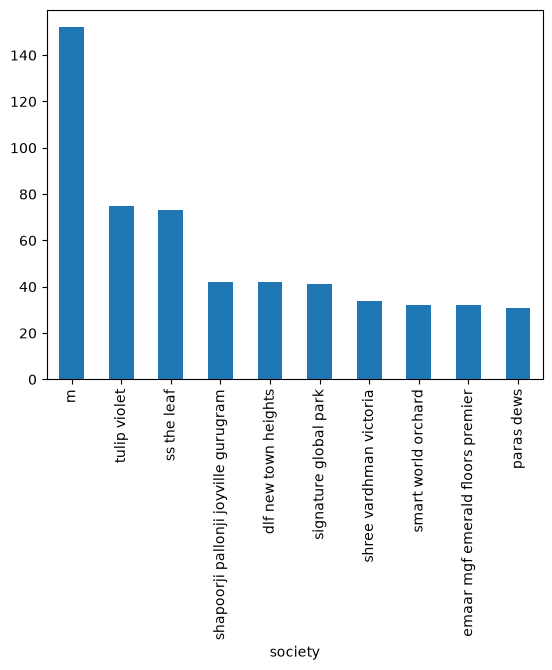

In [43]:
# top 10 socities
df[df['society'] != 'independent']['society'].value_counts().head(10).plot(kind='bar')

In [44]:
df['society'].isnull().sum()

np.int64(3)

In [45]:
df[df['society'].isnull()]

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,...,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area
1165,flat,NaN,0.6,NaN,sector 12,720.03,Carpet area: 720 (66.89 sq.m.),2,2,1.0,...,1,0,0,0,0,2,0,NaN,NaN,720.0
3076,flat,NaN,1.9,NaN,sector 67a,2143.74,Super Built up area 2200(204.39 sq.m.),4,4,3.0,...,0,0,0,0,0,2,62,2200.0,NaN,NaN
3406,flat,NaN,0.6,NaN,sector 78,1625.14,Built Up area: 1625 (150.97 sq.m.),2,2,NaN,...,0,0,0,0,0,1,0,NaN,1625.0,NaN


#### Observations

- Around 13% properties comes under independent tag.
- There are 675 societies. 
- The top 75 societies have 50 percent of the preperties and the rest 50 percent of the properties come under the remaining 600 societies
    - Very High (>100): Only 1 society has more than 100 listings.
    - High (50-100): 2 societies have between 50 to 100 listings.
    - Average (10-49): 92 societies fall in this range with 10 to 49 listings each.
    - Low (2-9): 273 societies have between 2 to 9 listings.
    - Very Low (1): A significant number, 308 societies, have only 1 listing.
- 1 missing value

### sector

In [46]:
# unique sectors
df['sector'].value_counts().shape

(264,)

<Axes: xlabel='sector'>

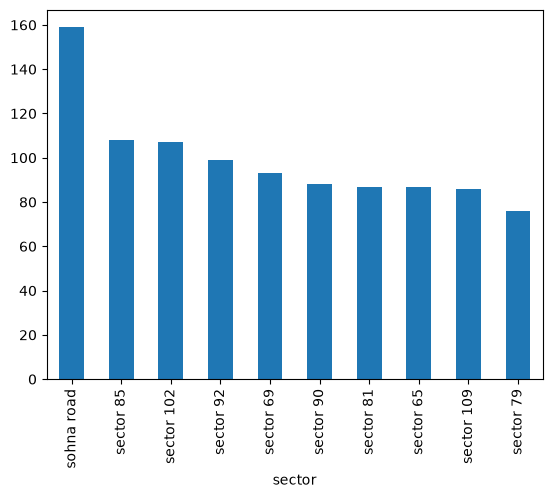

In [47]:
# top 10 sectors
df['sector'].value_counts().head(10).plot(kind='bar')

In [48]:
# Frequency distribution for sectors
sector_counts = df['sector'].value_counts()

sector_frequency_bins = {
    "Very High (>100)": (sector_counts > 100).sum(),
    "High (50-100)": ((sector_counts >= 50) & (sector_counts <= 100)).sum(),
    "Average (10-49)": ((sector_counts >= 10) & (sector_counts < 50)).sum(),
    "Low (2-9)": ((sector_counts > 1) & (sector_counts < 10)).sum(),
    "Very Low (1)": (sector_counts == 1).sum()
}

sector_frequency_bins

{'Very High (>100)': np.int64(3),
 'High (50-100)': np.int64(20),
 'Average (10-49)': np.int64(68),
 'Low (2-9)': np.int64(103),
 'Very Low (1)': np.int64(70)}

#### Observations

- There are a total of 104 unique sectors in the dataset.
- Frequency distribution of sectors:
    - Very High (>100): 3 sectors have more than 100 listings.
    - High (50-100): 25 sectors have between 50 to 100 listings.
    - Average (10-49): A majority, 60 sectors, fall in this range with 10 to 49 listings each.
    - Low (2-9): 16 sectors have between 2 to 9 listings.
    - Very Low (1): Interestingly, there are no sectors with only 1 listing.

### Price

In [49]:
df['price'].isnull().sum()

np.int64(28)

In [50]:
df['price'].describe()

count    3749.000000
mean        2.520327
std         2.969816
min         0.075000
25%         0.920000
50%         1.500000
75%         2.750000
max        31.500000
Name: price, dtype: float64

<Axes: xlabel='price', ylabel='Count'>

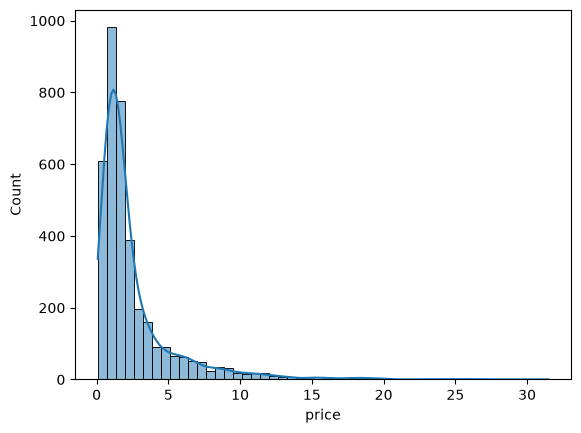

In [51]:
sns.histplot(df['price'], kde=True, bins=50)

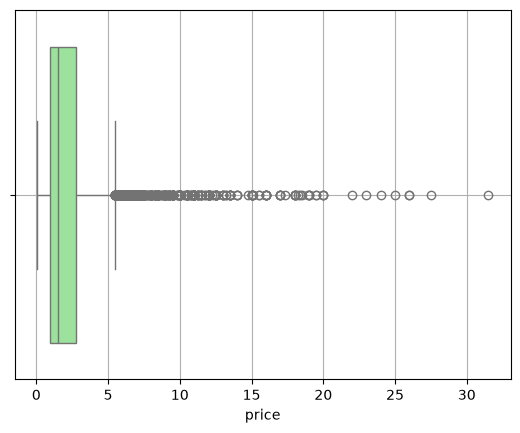

In [52]:
sns.boxplot(x=df['price'], color='lightgreen')
plt.grid()

- Descriptive Statistics:

    - Count: There are 3,660 non-missing price entries.
    - Mean Price: The average price is approximately 2.53 crores.
    - Median Price: The median (or 50th percentile) price is 1.52 crores.
    - Standard Deviation: The prices have a standard deviation of 2.98, indicating variability in the prices.
    - Range: Prices range from a minimum of 0.07 crores to a maximum of 31.5 crores.
    - IQR: The interquartile range (difference between 75th and 25th percentile) is from 0.95 crores to 2.75 crores.


- Visualizations:

    - Distribution: The histogram indicates that most properties are priced in the lower range (below 5 crores), with a few properties going beyond 10 crores.
    - Box Plot: The box plot showcases the spread of the data and potential outliers. Properties priced above approximately 10 crores might be considered outliers as they lie beyond the upper whisker of the box plot.
 

- Missing Values: There are 17 missing values in the price column.

In [53]:
# Skewness and Kurtosis
skewness = df['price'].skew()
kurtosis = df['price'].kurt()

print(skewness,kurtosis)

3.2796683407812233 14.953920165955928


**Skewness**: The price distribution has a skewness of approximately 3.28, indicating a positive skew. This means that the distribution tail is skewed to the right, which aligns with our observation from the histogram where most properties have prices on the lower end with a few high-priced properties.

**Kurtosis**: The kurtosis value is approximately 14.93. A kurtosis value greater than 3 indicates a distribution with heavier tails and more outliers compared to a normal distribution.

In [54]:
# Quantile Analysis
quantiles = df['price'].quantile([0.01, 0.05, 0.95, 0.99])

quantiles

0.01     0.250
0.05     0.370
0.95     8.500
0.99    15.308
Name: price, dtype: float64

Quantile Analysis:

- 1% Quantile: Only 1% of properties are priced below 0.25 crores.
- 5% Quantile: 5% of properties are priced below 0.37 crores.
- 95% Quantile: 95% of properties are priced below 8.5 crores.
- 99% Quantile: 99% of properties are priced below 15.26 crores, indicating that very few properties are priced above this value.

In [55]:
# Identify potential outliers using IQR method
Q1 = df['price'].describe()['25%']
Q3 = df['price'].describe()['75%']
IQR = Q3 - Q1

IQR

np.float64(1.83)

In [56]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(lower_bound, upper_bound)

-1.8250000000000002 5.495


In [57]:
outliers = df[(df['price'] < lower_bound) | (df['price'] > upper_bound)]
outliers.shape

(433, 23)

In [58]:
outliers['price'].describe()

count    433.000000
mean       9.213603
std        4.055215
min        5.500000
25%        6.440000
50%        8.000000
75%       10.560000
max       31.500000
Name: price, dtype: float64

Outliers Analysis (using IQR method):

- Based on the IQR method, there are 425 properties considered as outliers.
- These outliers have an average price of approximately 9.24 crores.
- The range for these outliers is from 5.46 crores to 31.5 crores.

<Axes: xlabel='price'>

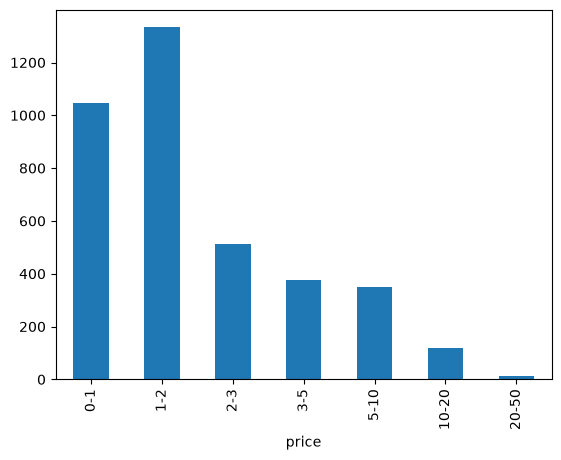

In [59]:
# price binning
bins = [0, 1, 2, 3, 5, 10, 20, 50]
bin_labels = ["0-1", "1-2", "2-3", "3-5", "5-10", "10-20", "20-50"]
pd.cut(df['price'], bins=bins, labels=bin_labels, right=False).value_counts().sort_index().plot(kind='bar')

- The majority of properties are priced in the "1-2 crores" and "2-3 crores" ranges.
- There's a significant drop in the number of properties priced above "5 crores."

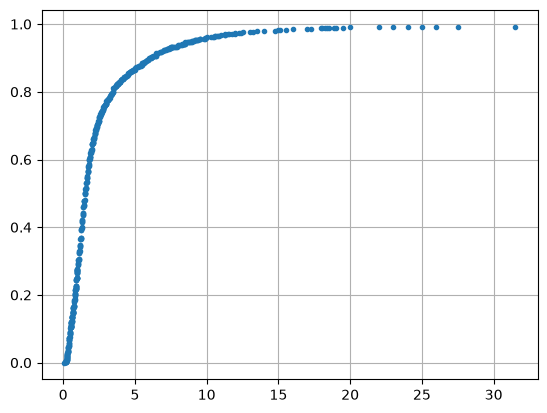

In [60]:
# ecdf plot
ecdf = df['price'].value_counts().sort_index().cumsum() / len(df['price'])
plt.plot(ecdf.index, ecdf, marker='.', linestyle='none')
plt.grid()

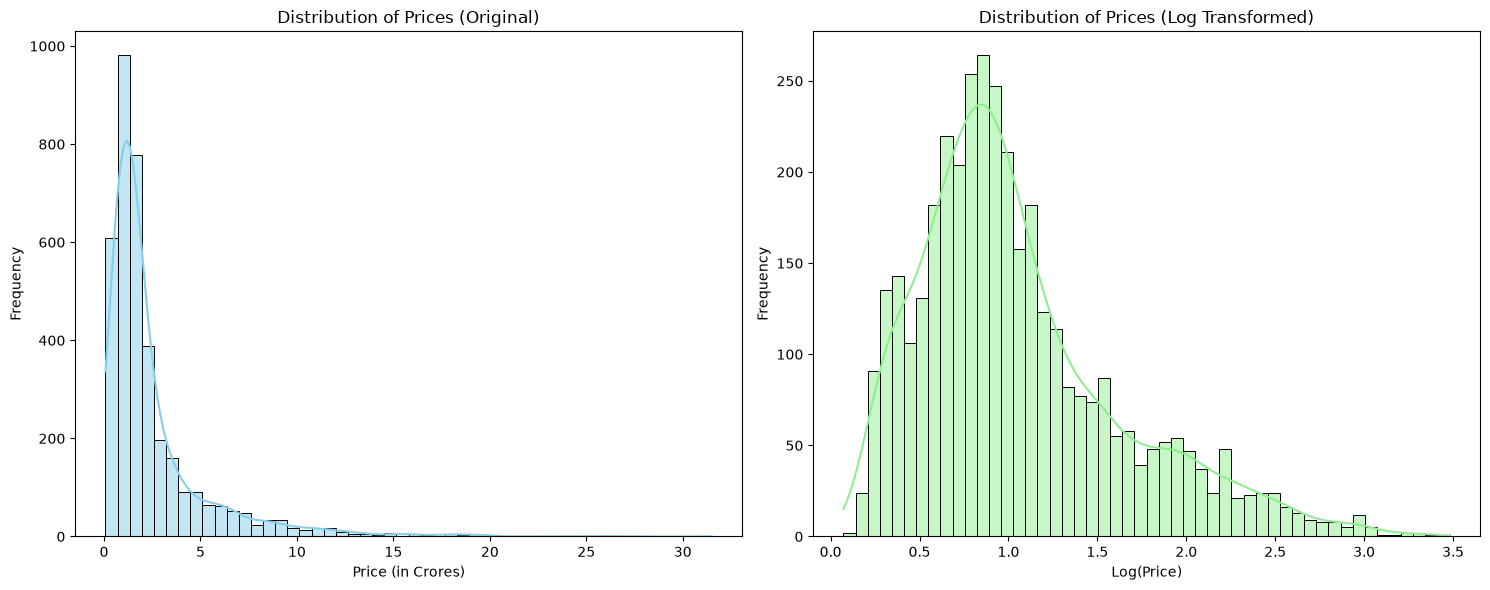

In [61]:
plt.figure(figsize=(15, 6))

# Distribution plot without log transformation
plt.subplot(1, 2, 1)
sns.histplot(df['price'], kde=True, bins=50, color='skyblue')
plt.title('Distribution of Prices (Original)')
plt.xlabel('Price (in Crores)')
plt.ylabel('Frequency')

# Distribution plot with log transformation
plt.subplot(1, 2, 2)
sns.histplot(np.log1p(df['price']), kde=True, bins=50, color='lightgreen')
plt.title('Distribution of Prices (Log Transformed)')
plt.xlabel('Log(Price)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

np.log1p(x): This function computes the natural logarithm of 1+x. 
It's designed to provide more accurate results for values of x that are very close to zero.

Using np.log1p helps in transforming the price column while ensuring that any value (including zero, if present) is handled appropriately. When we need to reverse the transformation, we can use np.expm1 which computes e^x-1

In [62]:
skewness = np.log1p(df['price']).skew()
kurtosis = np.log1p(df['price']).kurt()

print(skewness,kurtosis)

1.0730038088992258 0.9550277491021721


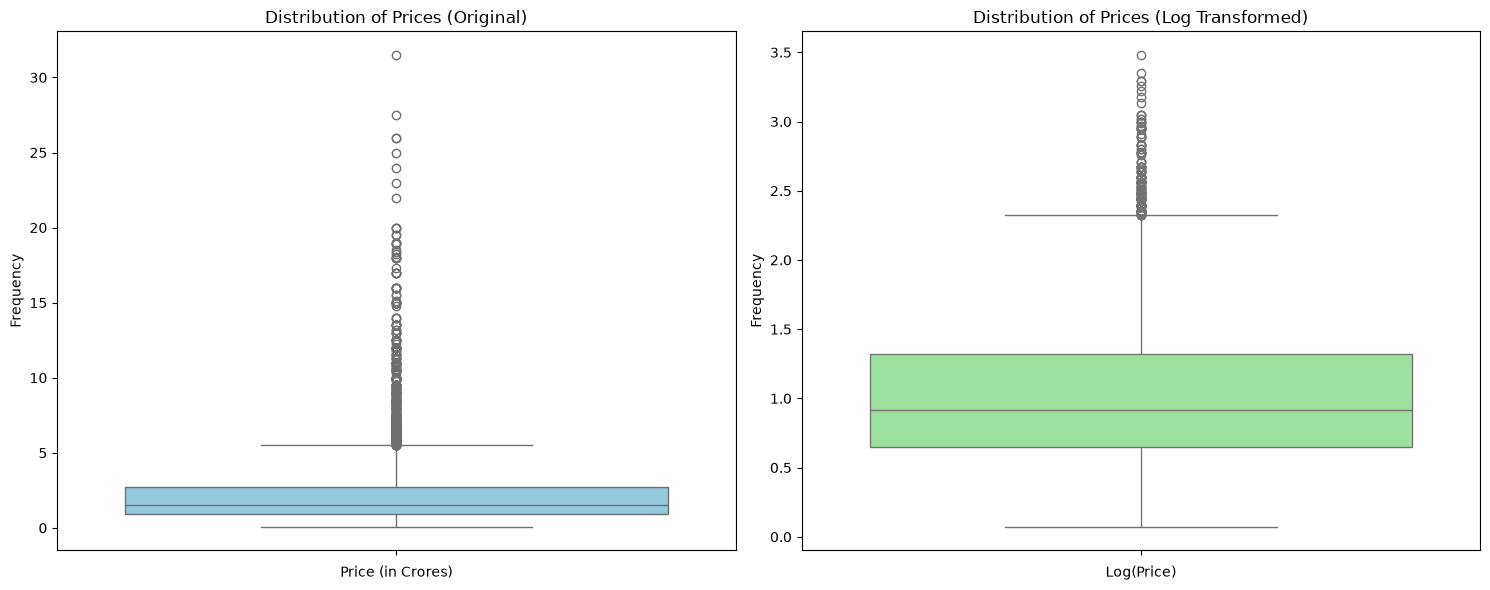

In [63]:
plt.figure(figsize=(15, 6))

# Distribution plot without log transformation
plt.subplot(1, 2, 1)
sns.boxplot(df['price'], color='skyblue')
plt.title('Distribution of Prices (Original)')
plt.xlabel('Price (in Crores)')
plt.ylabel('Frequency')

# Distribution plot with log transformation
plt.subplot(1, 2, 2)
sns.boxplot(np.log1p(df['price']), color='lightgreen')
plt.title('Distribution of Prices (Log Transformed)')
plt.xlabel('Log(Price)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

### price_per_sqft

In [64]:
df['price_per_sqft'].isnull().sum()

np.int64(2832)

In [65]:
df['price_per_sqft'].describe()

count       945.000000
mean      28251.213757
std       42849.177326
min           2.000000
25%       10085.000000
50%       19231.000000
75%       30247.000000
max      600000.000000
Name: price_per_sqft, dtype: float64

<Axes: xlabel='price_per_sqft', ylabel='Count'>

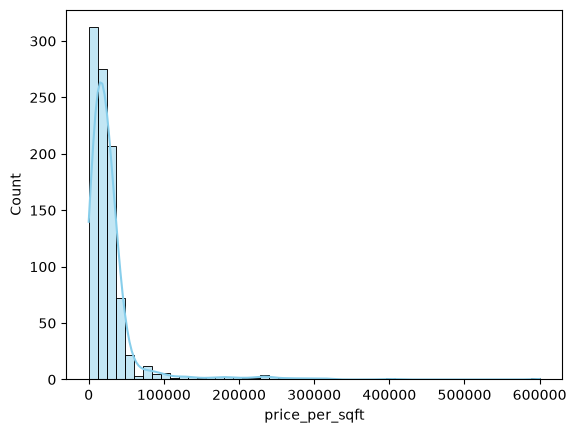

In [66]:
sns.histplot(df['price_per_sqft'], bins=50, color='skyblue', kde=True)

Most properties have a price_per_sqft ranging between approximately ₹0 and ₹40,000. There is a significant concentration in the lower range, with a few properties having exceptionally high price_per_sqft.

<Axes: ylabel='price_per_sqft'>

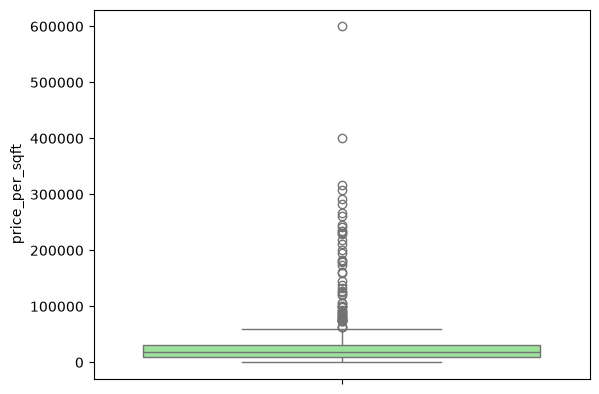

In [67]:
sns.boxplot(df['price_per_sqft'], color='lightgreen')

The box plot clearly shows several outliers, especially on the higher side. The interquartile range (IQR) is relatively compact, but there are many data points beyond the "whiskers" of the box plot, indicating potential outliers

#### Observations

- Potential Outliers
- Right Skewed
- 17 missing values

### bedRoom

In [68]:
df['bedRoom'].isnull().sum()

np.int64(0)

<Axes: xlabel='bedRoom'>

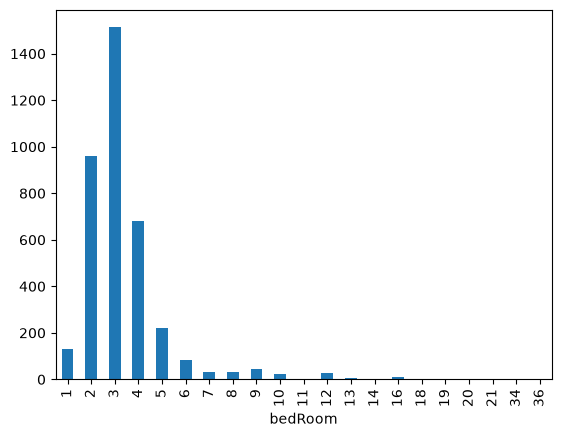

In [69]:
df['bedRoom'].value_counts().sort_index().plot(kind='bar')

<Axes: ylabel='proportion'>

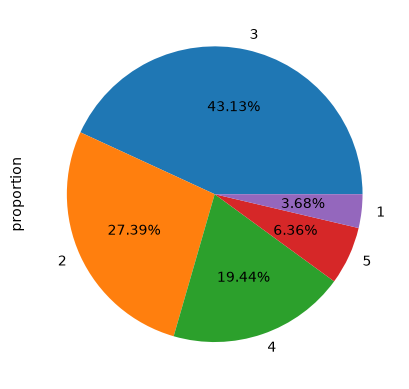

In [70]:
df['bedRoom'].value_counts(normalize=True).head().plot(kind='pie',autopct='%0.2f%%')

### bathroom

In [71]:
df['bathroom'].isnull().sum()

np.int64(0)

<Axes: xlabel='bathroom'>

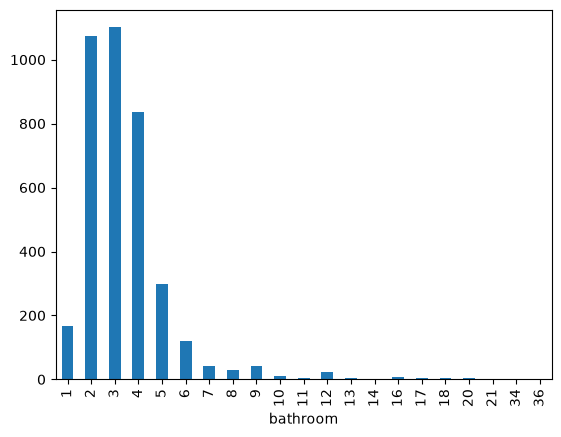

In [72]:
df['bathroom'].value_counts().sort_index().plot(kind='bar')

<Axes: ylabel='proportion'>

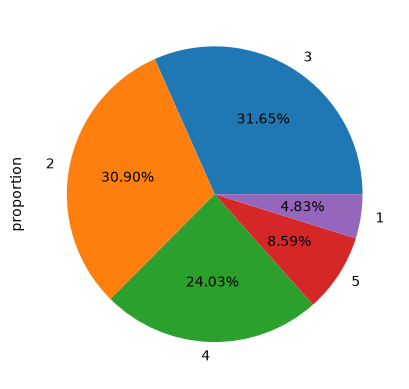

In [73]:
df['bathroom'].value_counts(normalize=True).head().plot(kind='pie',autopct='%0.2f%%')

In [74]:
df.head()

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,...,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area
0,flat,indiabulls centrum park,2.45,NaN,sector 103,2875.25,Super Built up area 2875(267.1 sq.m.),4,4,3.0,...,1,1,1,1,0,0,38,2875.0,NaN,NaN
1,house,project mianwali colony,2.00,14815.0,mianwali colony,1350.00,Built Up area: 1350 (125.42 sq.m.),5,5,2.0,...,0,0,0,0,0,0,0,NaN,1350.0,NaN
2,flat,paras dews,1.50,NaN,sector 106,2355.16,Super Built up area 2355(218.79 sq.m.)Built Up...,4,6,3.0,...,0,0,0,1,0,0,174,2355.0,1535.0,1403.000000
3,flat,rof ananda,0.38,NaN,sector 95,549.21,Carpet area: 549.17 (51.02 sq.m.),2,2,1.0,...,0,0,0,0,0,1,0,NaN,NaN,549.174178
4,flat,sare homes,0.68,NaN,sector 92,1298.21,Carpet area: 1298 (120.59 sq.m.),3,3,2.0,...,1,0,0,0,0,1,100,NaN,NaN,1298.000000


### balcony

In [75]:
df['balcony'].isnull().sum()

np.int64(85)

<Axes: xlabel='balcony'>

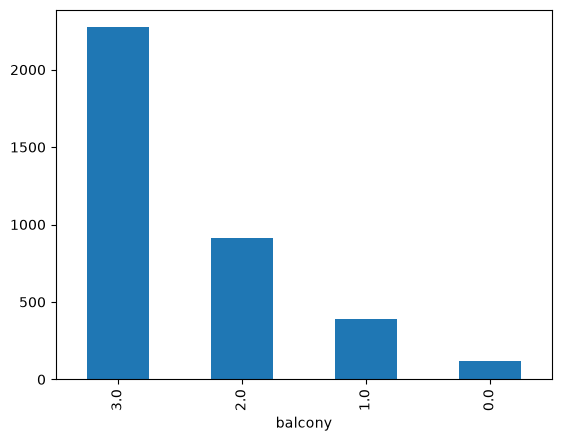

In [76]:
df['balcony'].value_counts().plot(kind='bar')

<Axes: ylabel='proportion'>

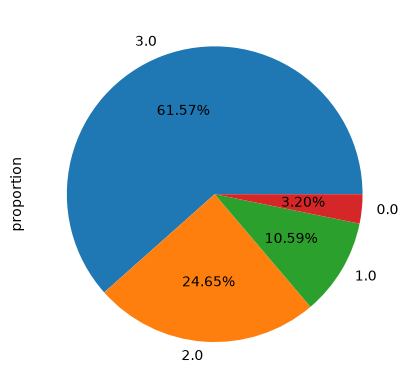

In [77]:
df['balcony'].value_counts(normalize=True).head().plot(kind='pie',autopct='%0.2f%%')

In [78]:
### floorNum

In [79]:
df.iloc[:,10:].head()

,floorNum,facing,agePossession,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area
0,11.0,East,Medium Aged,1,1,1,1,0,0,38,2875.0,NaN,NaN
1,3.0,East,Undefined,0,0,0,0,0,0,0,NaN,1350.0,NaN
2,11.0,North-West,Medium Aged,0,0,0,1,0,0,174,2355.0,1535.0,1403.000000
3,4.0,NaN,New,0,0,0,0,0,1,0,NaN,NaN,549.174178
4,11.0,North-West,Medium Aged,1,0,0,0,0,1,100,NaN,NaN,1298.000000


In [80]:
df['floorNum'].isnull().sum()

np.int64(20)

In [81]:
df['floorNum'].describe()

count    3757.000000
mean        6.675007
std         6.006612
min        -1.000000
25%         2.000000
50%         4.000000
75%        10.000000
max        51.000000
Name: floorNum, dtype: float64

<Axes: xlabel='floorNum'>

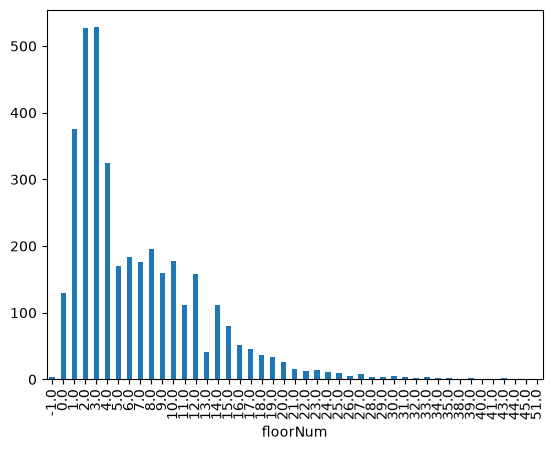

In [82]:
df['floorNum'].value_counts().sort_index().plot(kind='bar')

<Axes: ylabel='floorNum'>

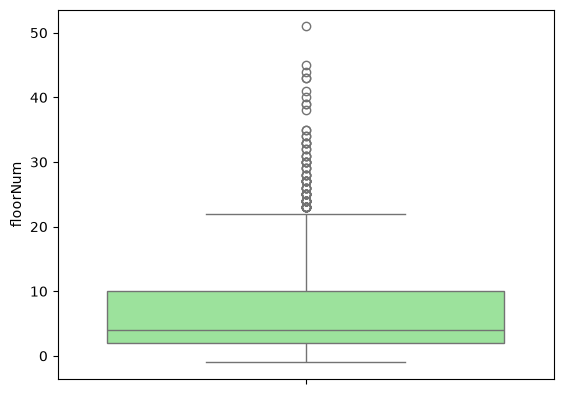

In [83]:
sns.boxplot(df['floorNum'], color='lightgreen')

- The majority of the properties lie between the ground floor (0) and the 25th floor.
- Floors 1 to 4 are particularly common, with the 3rd floor being the most frequent.
- There are a few properties located at higher floors, but their frequency is much lower.
- The box plot reveals that the majority of the properties are concentrated around the lower floors. The interquartile range (IQR) lies between approximately the 2nd and 10th floors.
- Data points beyond the "whiskers" of the box plot, especially on the higher side, indicate potential outliers.

### facing

In [84]:
df['facing'].isnull().sum()

np.int64(1092)

In [85]:
df['facing'].fillna('NA',inplace=True)

/var/folders/b_/s74htpc90ps4hdvn1vgvtjgr0000gn/T/ipykernel_1599/3692945726.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['facing'].fillna('NA',inplace=True)


In [86]:
df['facing'].value_counts()

facing
NA            1092
North-East     638
East           637
North          395
West           251
South          234
North-West     196
South-East     179
South-West     155
Name: count, dtype: int64

### agePossession

In [87]:
df['agePossession'].isnull().sum()

np.int64(0)

In [88]:
df['agePossession'].value_counts()

agePossession
Medium Aged           1664
Old                    584
New                    511
Under Construction     354
Very Old               336
Undefined              328
Name: count, dtype: int64

### areas

In [89]:
# super built up area
df['super_built_up_area'].isnull().sum()

np.int64(1906)

In [90]:
df['super_built_up_area'].describe()

count     1871.000000
mean      1927.356788
std        763.238085
min         89.000000
25%       1480.000000
50%       1828.000000
75%       2215.000000
max      10000.000000
Name: super_built_up_area, dtype: float64

<Axes: xlabel='super_built_up_area', ylabel='Count'>

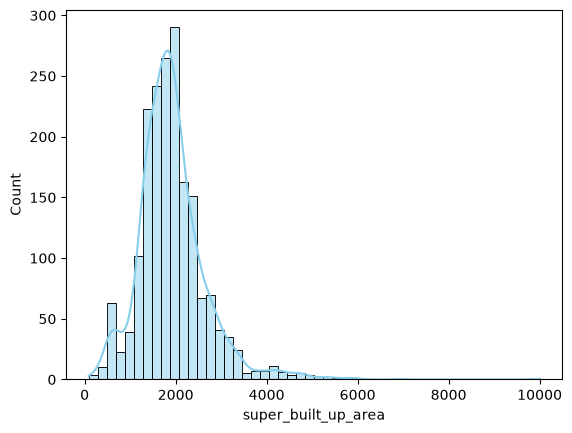

In [91]:
sns.histplot(df['super_built_up_area'].dropna(), bins=50, color='skyblue', kde=True)

<Axes: ylabel='super_built_up_area'>

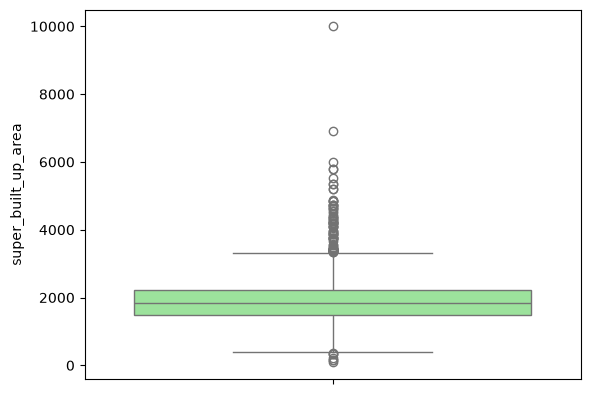

In [92]:
sns.boxplot(df['super_built_up_area'].dropna(), color='lightgreen')

- Most properties have a super built-up area ranging between approximately 1,000 sq.ft and 2,500 sq.ft.
- There are a few properties with a significantly larger area, leading to a right-skewed distribution.
- The interquartile range (IQR) lies between roughly 1,480 sq.ft and 2,215 sq.ft, indicating that the middle 50% of the properties fall within this range.
- There are several data points beyond the upper "whisker" of the box plot, indicating potential outliers. These are properties with an unusually large super built-up area.

In [93]:
# built up area
df['built_up_area'].isnull().sum()

np.int64(1986)

In [94]:
df['built_up_area'].describe()

count      1791.000000
mean       1797.803813
std       17446.555857
min           2.000000
25%         360.000000
50%        1186.000000
75%        1857.000000
max      737147.000000
Name: built_up_area, dtype: float64

<Axes: xlabel='built_up_area', ylabel='Count'>

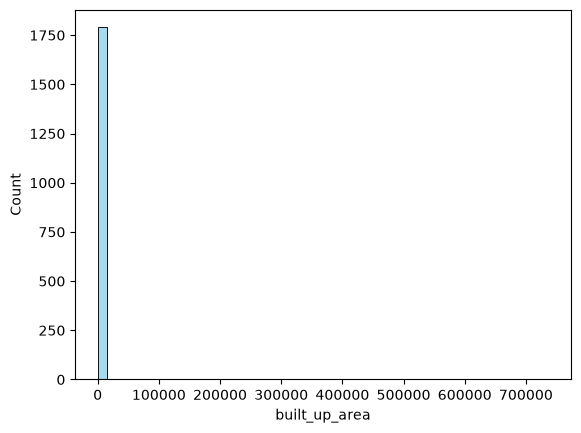

In [95]:
sns.histplot(df['built_up_area'].dropna(), bins=50, color='skyblue', kde=False)

<Axes: ylabel='built_up_area'>

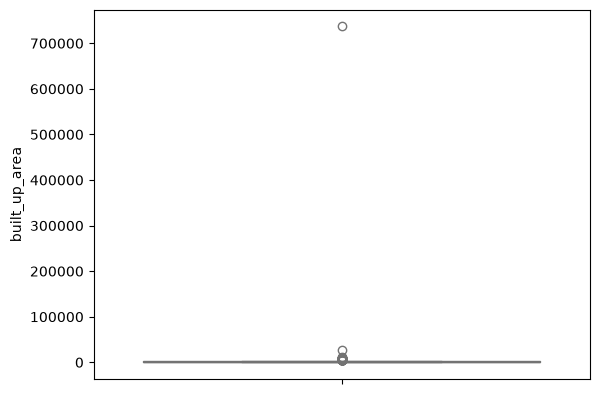

In [96]:
sns.boxplot(df['built_up_area'].dropna(), color='lightgreen')

- Most properties have a built-up area ranging roughly between 500 sq.ft and 3,500 sq.ft.
- There are very few properties with a much larger built-up area, leading to a highly right-skewed distribution.
- The box plot confirms the presence of significant outliers on the higher side. The data's interquartile range (IQR) is relatively compact, but the "whiskers" of the box plot are stretched due to the outliers.


The presence of extreme values, especially on the higher side, suggests that there may be outliers or data errors. This could also be due to some properties being exceptionally large, like a commercial complex or an entire building being listed.

In [97]:
# carpet area
df['carpet_area'].isnull().sum()

np.int64(1885)

In [98]:
df['carpet_area'].describe()

count      1892.000000
mean       2511.554375
std       22679.831863
min          15.000000
25%         830.000000
50%        1292.000000
75%        1786.250000
max      607936.000000
Name: carpet_area, dtype: float64

<Axes: xlabel='carpet_area', ylabel='Count'>

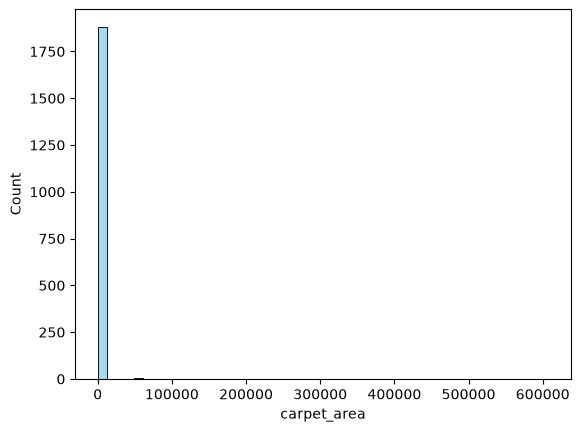

In [99]:
sns.histplot(df['carpet_area'].dropna(), bins=50, color='skyblue', kde=False)

<Axes: ylabel='carpet_area'>

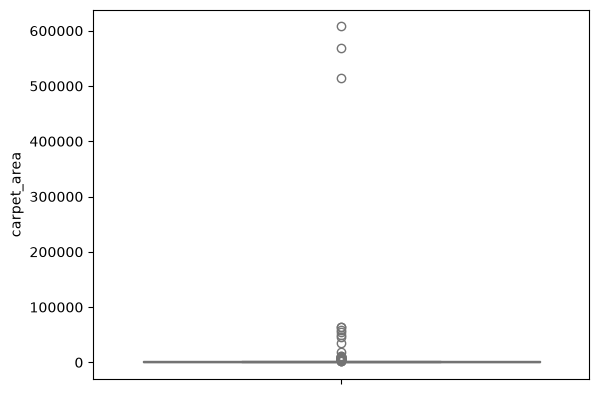

In [100]:
sns.boxplot(df['carpet_area'].dropna(), color='lightgreen')

In [101]:
df.iloc[:,16:]

,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area
0,1,0,0,38,2875.0,NaN,NaN
1,0,0,0,0,NaN,1350.0,NaN
2,1,0,0,174,2355.0,1535.0,1403.000000
3,0,0,1,0,NaN,NaN,549.174178
4,0,0,1,100,NaN,NaN,1298.000000
...,...,...,...,...,...,...,...
3896,0,0,1,0,NaN,NaN,2500.000000
3897,1,0,0,53,2150.0,1650.0,1350.000000
3898,0,1,1,61,1549.0,NaN,NaN
3900,0,0,0,55,NaN,750.0,650.000000


### additional rooms

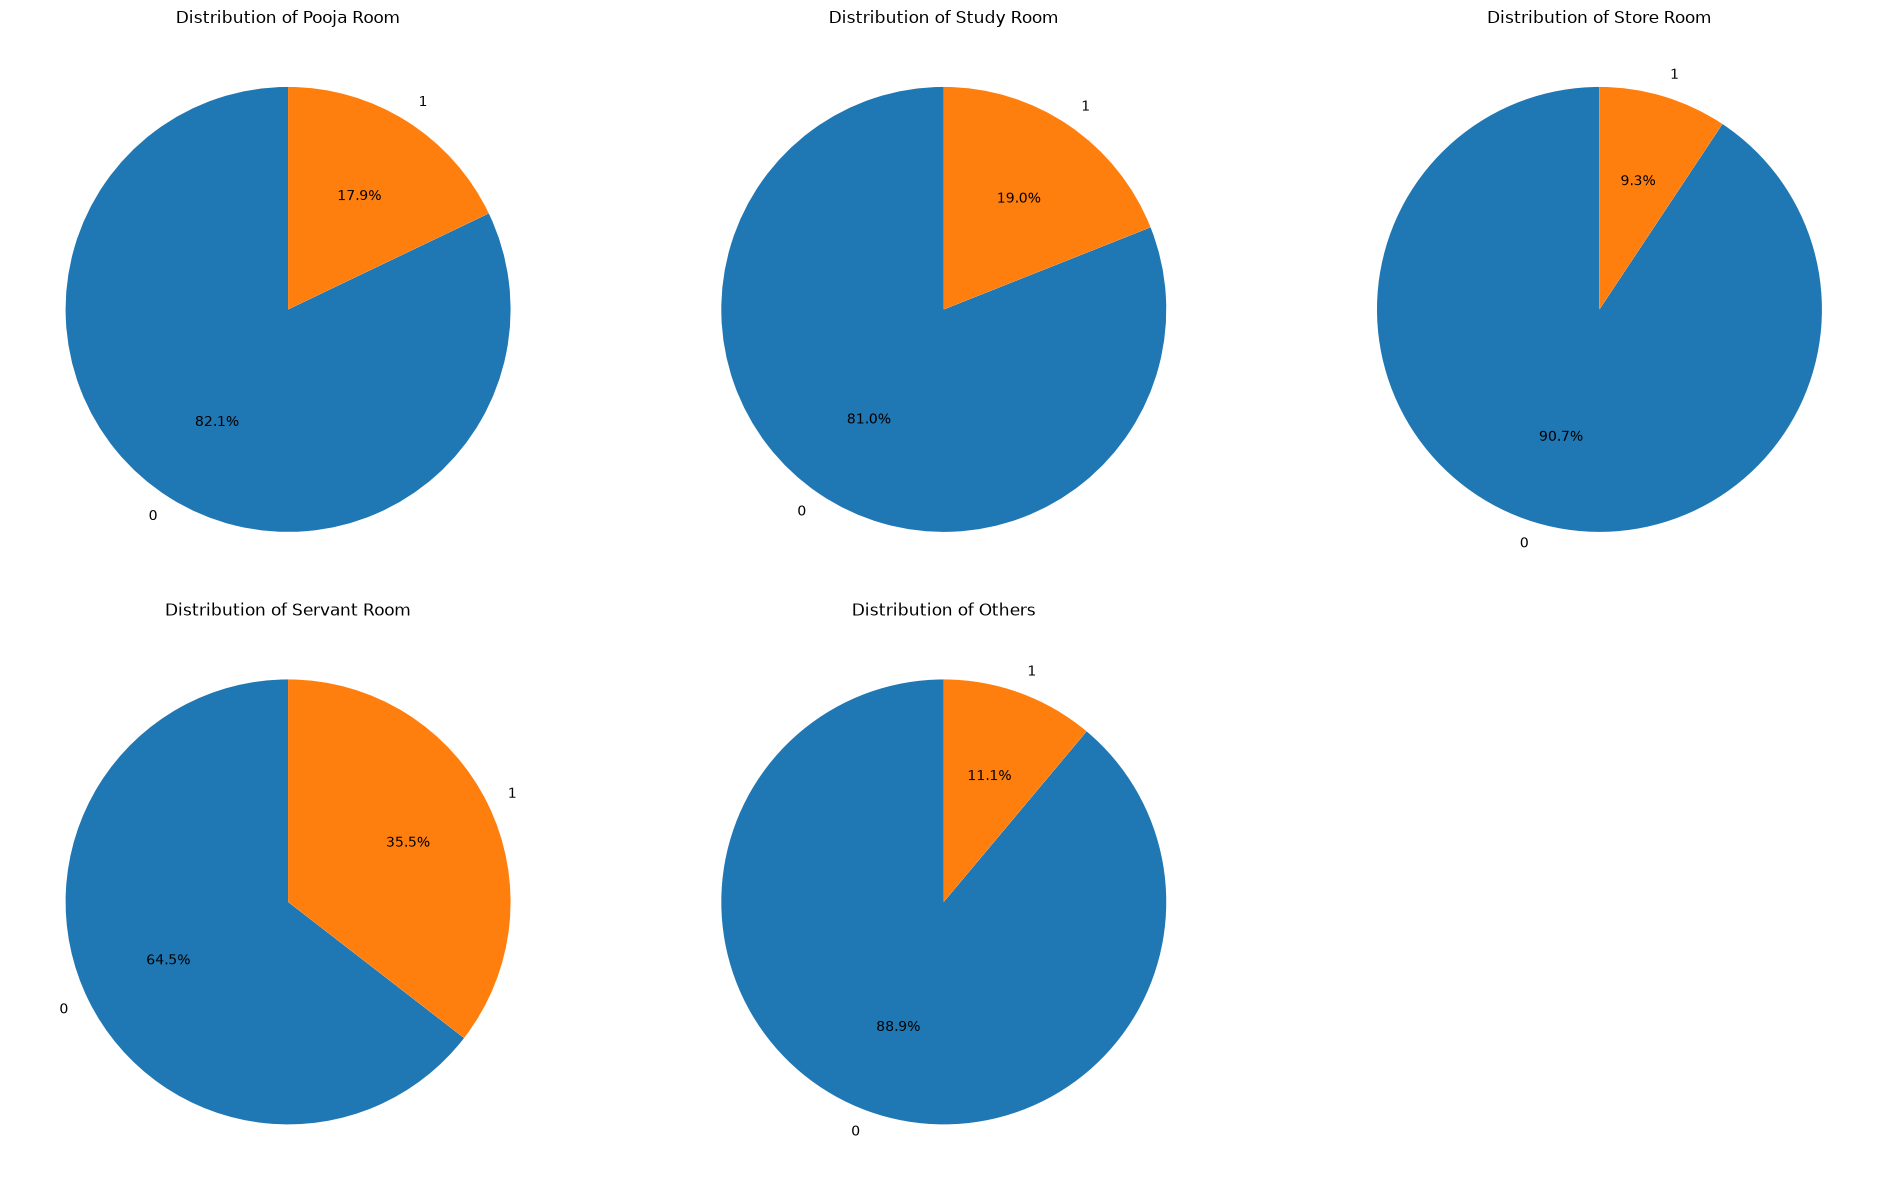

In [103]:
plt.figure(figsize=(20, 12))

# Create a subplot of pie charts for each room type
for idx, room in enumerate(["Pooja Room",	"Study Room",	"Store Room",	"Servant Room",'Others'], 1):
    ax = plt.subplot(2, 3, idx)
    df[room].value_counts().plot.pie(autopct='%1.1f%%', startangle=90, ax=ax)
    plt.title(f'Distribution of {room.title()}')
    plt.ylabel('')

plt.tight_layout()
plt.show()

### furnishing_type

In [105]:
df['furnishstatus'].value_counts()

furnishstatus
1    1515
2    1132
0    1130
Name: count, dtype: int64

<Axes: ylabel='count'>

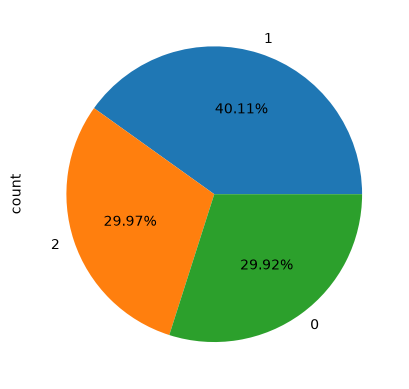

In [106]:
df['furnishstatus'].value_counts().plot(kind='pie',autopct='%0.2f%%')

### luxury score

In [107]:
df['luxury_score'].isnull().sum()

np.int64(0)

In [108]:
df['luxury_score'].describe()

count    3777.000000
mean       69.883770
std        53.515675
min         0.000000
25%        28.000000
50%        56.000000
75%       109.000000
max       174.000000
Name: luxury_score, dtype: float64

<Axes: xlabel='luxury_score', ylabel='Count'>

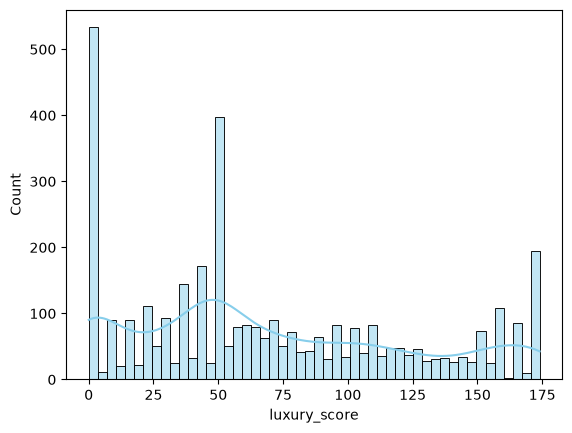

In [109]:
sns.histplot(df['luxury_score'], bins=50, color='skyblue', kde=True)

<Axes: ylabel='luxury_score'>

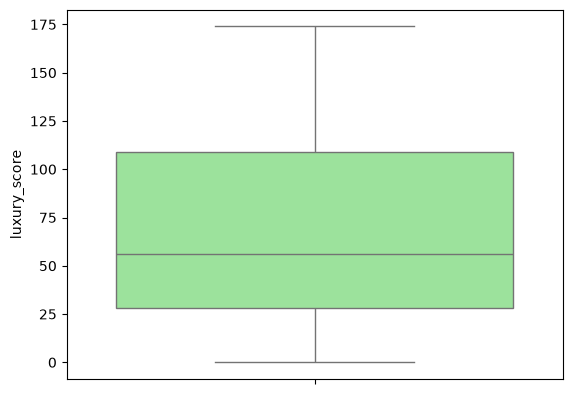

In [110]:
sns.boxplot(df['luxury_score'], color='lightgreen')

The luxury score distribution has multiple peaks, suggesting a multi-modal distribution. There's a significant number of properties with lower luxury scores (around 0-50), and another peak is observed around the 110-130 range.

The box plot reveals that the majority of the properties have luxury scores between approximately 30 and 110. The interquartile range (IQR) lies between these values.

In [111]:
df.head()

,property_type,society,price,price_per_sqft,sector,area,areaWithType,bedRoom,bathroom,balcony,...,Pooja Room,Study Room,Store Room,Servant Room,Others,furnishstatus,luxury_score,super_built_up_area,built_up_area,carpet_area
0,flat,indiabulls centrum park,2.45,NaN,sector 103,2875.25,Super Built up area 2875(267.1 sq.m.),4,4,3.0,...,1,1,1,1,0,0,38,2875.0,NaN,NaN
1,house,project mianwali colony,2.00,14815.0,mianwali colony,1350.00,Built Up area: 1350 (125.42 sq.m.),5,5,2.0,...,0,0,0,0,0,0,0,NaN,1350.0,NaN
2,flat,paras dews,1.50,NaN,sector 106,2355.16,Super Built up area 2355(218.79 sq.m.)Built Up...,4,6,3.0,...,0,0,0,1,0,0,174,2355.0,1535.0,1403.000000
3,flat,rof ananda,0.38,NaN,sector 95,549.21,Carpet area: 549.17 (51.02 sq.m.),2,2,1.0,...,0,0,0,0,0,1,0,NaN,NaN,549.174178
4,flat,sare homes,0.68,NaN,sector 92,1298.21,Carpet area: 1298 (120.59 sq.m.),3,3,2.0,...,1,0,0,0,0,1,100,NaN,NaN,1298.000000
